# GREI citations in Web of Science — maps of citing countries and US states, and citing Web of Science Categories

Reads the citation list made by the main notebook (`GREI_WoS_outputs/GREI_WoS_citation_edges_master.csv`) and makes:
1. **World choropleth** — citing papers by the countries in their author addresses
2. **US choropleth** — citing papers by US state in their author addresses
3. **Web of Science Categories** — of the citing papers, and a journal → category table

**How to run:** check the settings cell, then *Run All*. Maps are saved as interactive HTML files (and PNG images if
`kaleido` is installed) in `GREI_WoS_outputs/maps_and_categories/`, with all tables in one Excel workbook.

**Counting:** by default each citing paper counts **once per country** (or state, or category) it lists, however many
authors from there and however many of your DOIs it cites ("whole counting" of citing documents). Set
`COUNT_UNIT = "citations"` to count citation relationships (a paper citing 3 of your DOIs counts 3 times) instead.

## 1. Settings

In [1]:
from pathlib import Path

BASE_DIR    = Path.cwd()                                      # the project folder (where the main notebook is)
MASTER_FILE = BASE_DIR / "GREI_WoS_outputs" / "GREI_WoS_citation_edges_master.csv"
OUT_DIR     = BASE_DIR / "GREI_WoS_outputs" / "maps_and_categories"

COUNT_UNIT      = "documents"   # "documents" = each citing paper once; "citations" = each paper x target DOI pair
AUTHOR_SCOPE    = "all"         # "all" = every author address on the paper; "corresponding" = corresponding author only
LOG_COLOR_SCALE = True          # True = log colour scale (keeps USA/China from washing out every other country)
MAP_PROJECTION  = "natural earth"   # or "robinson", "equirectangular", ...
MAP_CENTER_LON  = 0             # central meridian of the world map: 0 puts the Americas on the left, Asia on the right
TOP_N           = 25            # rows shown in the bar charts / tables
SAVE_PNG        = True          # also save PNG images of the maps (needs the 'kaleido' package)

## 2. Load the citation list

In [2]:
import re, sys, math, subprocess
import pandas as pd
import numpy as np
from collections import Counter, defaultdict

try:
    import plotly.express as px
except ImportError:                                  # install once, into the same Python as this notebook
    subprocess.check_call([sys.executable, "-m", "pip", "install", "plotly"])
    import plotly.express as px
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

pd.set_option("display.max_colwidth", 80)
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEP = " | "            # how the main notebook separates multiple values
ADDR_SEP = " || "      # ... and multiple full addresses

import html
def unescape_text(v):
    """Undo HTML escaping (e.g. '&amp;' -> '&'); TDM Studio escapes the embedded WoS text twice."""
    if not isinstance(v, str) or "&" not in v:
        return v
    for _ in range(3):
        u = html.unescape(v)
        if u == v:
            break
        v = u
    return v

edges = pd.read_csv(MASTER_FILE, dtype=str, keep_default_na=False)
for c in edges.columns:
    if c.startswith("citing_") or c in ("target_title", "attributes_titles", "attributes_publisher"):
        edges[c] = edges[c].map(unescape_text)
docs = edges.drop_duplicates("citing_doc_key").copy()           # one row per citing paper
print(f"Citation relationships (paper x target DOI): {len(edges):,}")
print(f"Unique citing papers                        : {len(docs):,}")
print(f"Target DOIs cited                           : {edges.target_doi_normalized.nunique():,}")

UNIT_DF = docs if COUNT_UNIT == "documents" else edges
UNIT_LABEL = "citing papers" if COUNT_UNIT == "documents" else "citations"
print(f"\nCounting unit: {UNIT_LABEL}  |  addresses used: {AUTHOR_SCOPE}")

Citation relationships (paper x target DOI): 807
Unique citing papers                        : 728
Target DOIs cited                           : 694

Counting unit: citing papers  |  addresses used: all


## 3. Country names → ISO codes
Web of Science writes country names its own way ("USA", "Peoples R China", "England", "U Arab Emirates" …).
They are mapped to ISO 3-letter codes for the map. England, Scotland, Wales and North Ireland are combined as the
United Kingdom on the map (they are kept separately in the table). **Any name not recognised is listed below** —
add it to `EXTRA_COUNTRY_CODES` in this cell and re-run.

In [3]:
EXTRA_COUNTRY_CODES = {
    # "Some WoS Name": "ISO",
}

ISO3 = {
 # --- Web of Science spellings ---
 "usa": "USA", "peoples r china": "CHN", "england": "GBR", "scotland": "GBR", "wales": "GBR", "north ireland": "GBR",
 "northern ireland": "GBR", "u arab emirates": "ARE", "turkiye": "TUR", "south korea": "KOR", "north korea": "PRK",
 "russia": "RUS", "taiwan": "TWN", "iran": "IRN", "vietnam": "VNM", "czech republic": "CZE", "bosnia & herceg": "BIH",
 "bosnia & herzegovina": "BIH", "trinidad tobago": "TTO", "cote ivoire": "CIV", "dem rep congo": "COD",
 "rep congo": "COG", "papua n guinea": "PNG", "byelarus": "BLR", "brunei": "BRN", "laos": "LAO", "macedonia": "MKD",
 "north macedonia": "MKD", "syria": "SYR", "tanzania": "TZA", "venezuela": "VEN", "bolivia": "BOL", "moldova": "MDA",
 "kosovo": "XKX", "palestine": "PSE", "libya": "LBY", "swaziland": "SWZ", "eswatini": "SWZ", "cape verde": "CPV",
 "cabo verde": "CPV", "micronesia": "FSM", "st kitts & nevi": "KNA", "antigua & barbu": "ATG", "guinea bissau": "GNB",
 "guinea-bissau": "GNB", "sao tome & prin": "STP", "timor-leste": "TLS", "east timor": "TLS", "bahamas": "BHS",
 "gambia": "GMB", "cent afr republ": "CAF", "equat guinea": "GNQ", "solomon isl": "SLB", "marshall island": "MHL",
 "st lucia": "LCA", "st vincent": "VCT", "fr polynesia": "PYF", "fr guiana": "GUF", "french guiana": "GUF",
 "new caledonia": "NCL", "guadeloupe": "GLP", "martinique": "MTQ", "reunion": "REU", "faroe islands": "FRO",
 "greenland": "GRL", "puerto rico": "PRI", "hong kong": "HKG", "macau": "MAC", "macao": "MAC", "vatican": "VAT",
 "monaco": "MCO", "liechtenstein": "LIE", "san marino": "SMR", "andorra": "AND", "w ind assoc st": "VCT",
 "neth antilles": "CUW", "curacao": "CUW", "bermuda": "BMU", "cayman islands": "CYM", "gibraltar": "GIB",
 "guam": "GUM", "mayotte": "MYT", "montserrat": "MSR", "turks & caicos": "TCA", "british virgin isl": "VGB",
 "us virgin isl": "VIR", "american samoa": "ASM", "cook islands": "COK", "niue": "NIU", "palau": "PLW",
 "nauru": "NRU", "tuvalu": "TUV", "kiribati": "KIR", "tonga": "TON", "samoa": "WSM", "western samoa": "WSM",
 "vanuatu": "VUT", "fiji": "FJI", "maldives": "MDV", "bhutan": "BTN", "nepal": "NPL", "myanmar": "MMR",
 "burma": "MMR", "cambodia": "KHM", "mongolia": "MNG", "kyrgyzstan": "KGZ", "tajikistan": "TJK",
 "turkmenistan": "TKM", "uzbekistan": "UZB", "kazakhstan": "KAZ", "azerbaijan": "AZE", "armenia": "ARM",
 "georgia": "GEO", "serbia": "SRB", "montenegro": "MNE", "serbia monteneg": "SRB", "yugoslavia": "SRB",
 # --- standard names ---
 "afghanistan": "AFG", "albania": "ALB", "algeria": "DZA", "angola": "AGO", "argentina": "ARG", "australia": "AUS",
 "austria": "AUT", "bahrain": "BHR", "bangladesh": "BGD", "barbados": "BRB", "belarus": "BLR", "belgium": "BEL",
 "belize": "BLZ", "benin": "BEN", "botswana": "BWA", "brazil": "BRA", "bulgaria": "BGR", "burkina faso": "BFA",
 "burundi": "BDI", "cameroon": "CMR", "canada": "CAN", "chad": "TCD", "chile": "CHL", "china": "CHN",
 "colombia": "COL", "comoros": "COM", "costa rica": "CRI", "croatia": "HRV", "cuba": "CUB", "cyprus": "CYP",
 "denmark": "DNK", "djibouti": "DJI", "dominica": "DMA", "dominican rep": "DOM", "dominican republic": "DOM",
 "ecuador": "ECU", "egypt": "EGY", "el salvador": "SLV", "eritrea": "ERI", "estonia": "EST", "ethiopia": "ETH",
 "finland": "FIN", "france": "FRA", "gabon": "GAB", "germany": "DEU", "ghana": "GHA", "greece": "GRC",
 "grenada": "GRD", "guatemala": "GTM", "guinea": "GIN", "guyana": "GUY", "haiti": "HTI", "honduras": "HND",
 "hungary": "HUN", "iceland": "ISL", "india": "IND", "indonesia": "IDN", "iraq": "IRQ", "ireland": "IRL",
 "israel": "ISR", "italy": "ITA", "jamaica": "JAM", "japan": "JPN", "jordan": "JOR", "kenya": "KEN",
 "kuwait": "KWT", "latvia": "LVA", "lebanon": "LBN", "lesotho": "LSO", "liberia": "LBR", "lithuania": "LTU",
 "luxembourg": "LUX", "madagascar": "MDG", "malawi": "MWI", "malaysia": "MYS", "mali": "MLI", "malta": "MLT",
 "mauritania": "MRT", "mauritius": "MUS", "mexico": "MEX", "morocco": "MAR", "mozambique": "MOZ",
 "namibia": "NAM", "netherlands": "NLD", "new zealand": "NZL", "nicaragua": "NIC", "niger": "NER",
 "nigeria": "NGA", "norway": "NOR", "oman": "OMN", "pakistan": "PAK", "panama": "PAN", "paraguay": "PRY",
 "peru": "PER", "philippines": "PHL", "poland": "POL", "portugal": "PRT", "qatar": "QAT", "romania": "ROU",
 "rwanda": "RWA", "saudi arabia": "SAU", "senegal": "SEN", "seychelles": "SYC", "sierra leone": "SLE",
 "singapore": "SGP", "slovakia": "SVK", "slovenia": "SVN", "somalia": "SOM", "south africa": "ZAF",
 "south sudan": "SSD", "spain": "ESP", "sri lanka": "LKA", "sudan": "SDN", "suriname": "SUR", "sweden": "SWE",
 "switzerland": "CHE", "thailand": "THA", "togo": "TGO", "tunisia": "TUN", "turkey": "TUR", "uganda": "UGA",
 "ukraine": "UKR", "united kingdom": "GBR", "uk": "GBR", "united states": "USA", "uruguay": "URY", "yemen": "YEM",
 "zambia": "ZMB", "zimbabwe": "ZWE", "korea": "KOR", "republic of korea": "KOR", "viet nam": "VNM",
 "czechia": "CZE", "united arab emirates": "ARE", "ivory coast": "CIV",
}
ISO3.update({k.lower(): v for k, v in EXTRA_COUNTRY_CODES.items()})

def country_code(name):
    key = re.sub(r"\s+", " ", str(name).strip().lower().replace(".", ""))
    return ISO3.get(key)

def split_vals(v):
    return [x.strip() for x in str(v).split(SEP) if x.strip()] if v else []

COUNTRY_COL = "citing_countries" if AUTHOR_SCOPE == "all" else "citing_corresponding_countries"
names = Counter(n for v in UNIT_DF[COUNTRY_COL] for n in split_vals(v))
unmatched = {n: c for n, c in names.items() if not country_code(n)}
print(f"Distinct WoS country names: {len(names)} | not recognised: {len(unmatched)}")
if unmatched:
    print("⚠️ Add these to EXTRA_COUNTRY_CODES (with their ISO 3-letter code) and re-run:")
    display(pd.Series(unmatched, name=UNIT_LABEL).sort_values(ascending=False).to_frame())

Distinct WoS country names: 99 | not recognised: 0


## 4. World map — citing countries

In [4]:
def country_table(df):
    rows = []
    for _, r in df.iterrows():
        codes = {}                                   # one count per paper per ISO country (UK nations merged)
        for n in split_vals(r[COUNTRY_COL]):
            c = country_code(n)
            if c:
                codes.setdefault(c, n)
        for c in codes:
            rows.append(c)
    t = pd.Series(Counter(rows), name=UNIT_LABEL).rename_axis("iso3").reset_index()
    return t.sort_values(UNIT_LABEL, ascending=False).reset_index(drop=True)

WORLD = country_table(UNIT_DF)
PRETTY = {"USA": "United States", "GBR": "United Kingdom", "CHN": "China", "ARE": "United Arab Emirates",
          "KOR": "South Korea", "PRK": "North Korea", "TUR": "Türkiye", "TWN": "Taiwan", "RUS": "Russia",
          "IRN": "Iran", "VNM": "Vietnam", "CZE": "Czech Republic", "BIH": "Bosnia and Herzegovina",
          "TTO": "Trinidad and Tobago", "CIV": "Côte d'Ivoire", "COD": "DR Congo", "COG": "Republic of the Congo",
          "PNG": "Papua New Guinea", "MKD": "North Macedonia", "SWZ": "Eswatini", "CPV": "Cabo Verde",
          "KNA": "Saint Kitts and Nevis", "ATG": "Antigua and Barbuda", "STP": "São Tomé and Príncipe",
          "CAF": "Central African Republic", "GNQ": "Equatorial Guinea", "SLB": "Solomon Islands",
          "MHL": "Marshall Islands", "LCA": "Saint Lucia", "VCT": "Saint Vincent and the Grenadines",
          "PYF": "French Polynesia", "GUF": "French Guiana", "FSM": "Micronesia", "LAO": "Laos", "BRN": "Brunei",
          "SYR": "Syria", "TZA": "Tanzania", "VEN": "Venezuela", "BOL": "Bolivia", "MDA": "Moldova",
          "PSE": "Palestine", "TLS": "Timor-Leste", "GNB": "Guinea-Bissau", "DOM": "Dominican Republic",
          "HKG": "Hong Kong", "MAC": "Macau", "PRI": "Puerto Rico", "CUW": "Curaçao"}
code_to_name = {}
for n in names:
    c = country_code(n)
    if c and c not in code_to_name:
        code_to_name[c] = PRETTY.get(c, n)
WORLD.insert(1, "country", WORLD.iso3.map(code_to_name))
WORLD["share_%"] = (100 * WORLD[UNIT_LABEL] / len(UNIT_DF)).round(1)
no_country = sum(1 for v in UNIT_DF[COUNTRY_COL] if not split_vals(v))
print(f"{len(WORLD)} countries | {UNIT_LABEL} with no country recorded: {no_country:,}")
display(WORLD.head(TOP_N))

def legend_title(place):
    """Colour-bar title that states the counting rule, e.g. 'Citing papers / (each counted once per state)'."""
    return f"{UNIT_LABEL.capitalize()}<br><sup>each counted once<br>per {place}</sup>"

def colour_bar(fig, values, title):
    """Log10 colour with the colour bar labelled in real counts (or a plain bar when LOG_COLOR_SCALE is False)."""
    if not LOG_COLOR_SCALE:
        fig.update_layout(coloraxis_colorbar=dict(title=title))
        return
    mx = max(values.max(), 1)
    ticks = [t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000] if t <= mx * 1.01] or [1]
    fig.update_layout(coloraxis_colorbar=dict(title=title, tickvals=[math.log10(t) for t in ticks],
                                              ticktext=[str(t) for t in ticks]))

COUNT_RULE = {"documents": "each citing paper is counted once per {place}, however many of its authors are there",
              "citations": "each citation (paper x cited output) is counted once per {place}, however many of the paper's authors are there"}[COUNT_UNIT]

plot_df = WORLD.copy()
color_col = UNIT_LABEL
if LOG_COLOR_SCALE:
    plot_df["log10"] = np.log10(plot_df[UNIT_LABEL].clip(lower=1))
    color_col = "log10"
fig_world = px.choropleth(plot_df, locations="iso3", color=color_col, hover_name="country",
                          hover_data={UNIT_LABEL: True, "share_%": True, "iso3": False, color_col: False},
                          color_continuous_scale="Blues", projection=MAP_PROJECTION,
                          title=(f"Countries of authors of Web of Science papers citing GREI/NIH outputs"
                                 f"<br><sup>{UNIT_LABEL.capitalize()}, n = {len(UNIT_DF):,}; "
                                 f"{COUNT_RULE.format(place='country')}</sup>"))
colour_bar(fig_world, plot_df[UNIT_LABEL], legend_title("country"))
fig_world.update_geos(showcountries=True, countrycolor="#999", showcoastlines=False, showframe=False,
                      projection_rotation=dict(lon=MAP_CENTER_LON, lat=0, roll=0))
fig_world.update_layout(margin=dict(l=0, r=0, t=70, b=0))
fig_world.show()

97 countries | citing papers with no country recorded: 2


,iso3,country,citing papers,share_%
0,USA,United States,640,87.9
1,DEU,Germany,65,8.9
2,GBR,United Kingdom,55,7.6
3,CAN,Canada,39,5.4
4,CHN,China,37,5.1
5,FRA,France,30,4.1
6,CHE,Switzerland,22,3.0
7,BRA,Brazil,19,2.6
8,ESP,Spain,17,2.3
9,NLD,Netherlands,16,2.2


## 5. US map — citing states
States are read from the US author addresses (e.g. "Chicago, IL 60611 USA").
**Counting:** a citing paper counts **once for each state** that appears in its author addresses. Two authors from
Illinois on the same paper count once for Illinois; a paper with authors in Illinois and California counts once for
each. (The same rule is used for countries on the world map.)

In [5]:
US_STATES = {"AL","AK","AZ","AR","CA","CO","CT","DE","DC","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA","ME","MD",
             "MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR","PA","RI","SC","SD",
             "TN","TX","UT","VT","VA","WA","WV","WI","WY","PR","GU","VI"}
STATE_NAMES = dict(AL="Alabama",AK="Alaska",AZ="Arizona",AR="Arkansas",CA="California",CO="Colorado",CT="Connecticut",
    DE="Delaware",DC="District of Columbia",FL="Florida",GA="Georgia",HI="Hawaii",ID="Idaho",IL="Illinois",IN="Indiana",
    IA="Iowa",KS="Kansas",KY="Kentucky",LA="Louisiana",ME="Maine",MD="Maryland",MA="Massachusetts",MI="Michigan",
    MN="Minnesota",MS="Mississippi",MO="Missouri",MT="Montana",NE="Nebraska",NV="Nevada",NH="New Hampshire",
    NJ="New Jersey",NM="New Mexico",NY="New York",NC="North Carolina",ND="North Dakota",OH="Ohio",OK="Oklahoma",
    OR="Oregon",PA="Pennsylvania",RI="Rhode Island",SC="South Carolina",SD="South Dakota",TN="Tennessee",TX="Texas",
    UT="Utah",VT="Vermont",VA="Virginia",WA="Washington",WV="West Virginia",WI="Wisconsin",WY="Wyoming",
    PR="Puerto Rico",GU="Guam",VI="US Virgin Islands")
_STATE_ZIP = re.compile(r"\b([A-Z]{2})\s+\d{5}(?:-\d{4})?\s+USA\s*$")
_STATE_NOZIP = re.compile(r",\s*([A-Z]{2})\s+USA\s*$")

ADDR_COL = "citing_affiliations_raw" if AUTHOR_SCOPE == "all" else "citing_corresponding_address_raw"

def us_states(raw):
    out, us_no_state = set(), 0
    for a in str(raw).split(ADDR_SEP):
        a = re.sub(r"^\[[^\]]*\]\s*", "", a.strip())          # drop the "[1] " address number
        if not a.upper().endswith("USA"):
            continue
        m = _STATE_ZIP.search(a) or _STATE_NOZIP.search(a)
        if m and m.group(1) in US_STATES:
            out.add(m.group(1))
        else:
            us_no_state += 1
    return out, us_no_state

state_counts, us_papers, missing_state = Counter(), 0, 0
for raw in UNIT_DF[ADDR_COL]:
    st, miss = us_states(raw)
    state_counts.update(st)
    us_papers += bool(st or miss)
    missing_state += miss
US = pd.Series(state_counts, name=UNIT_LABEL).rename_axis("state").reset_index()
US.insert(1, "state_name", US.state.map(STATE_NAMES))
US = US.sort_values(UNIT_LABEL, ascending=False).reset_index(drop=True)
print(f"{UNIT_LABEL} with a US address: {us_papers:,} | states found: {len(US)} | "
      f"US addresses where no state could be read: {missing_state:,}")
display(US.head(TOP_N))

plot_us = US[US.state.isin(US_STATES - {"PR", "GU", "VI"})].copy()     # territories are listed but not mapped
color_col = UNIT_LABEL
if LOG_COLOR_SCALE:
    plot_us["log10"] = np.log10(plot_us[UNIT_LABEL].clip(lower=1))
    color_col = "log10"
fig_us = None if plot_us.empty else px.choropleth(plot_us, locations="state", locationmode="USA-states", scope="usa", color=color_col,
                       hover_name="state_name", hover_data={UNIT_LABEL: True, "state": False, color_col: False},
                       color_continuous_scale="Blues",
                       title=(f"US states of authors of Web of Science papers citing GREI/NIH outputs"
                              f"<br><sup>{UNIT_LABEL.capitalize()} with at least one US author, n = {us_papers:,}; "
                              f"{COUNT_RULE.format(place='state')}</sup>"))
if fig_us is None:
    print("No US states found - US map not drawn.")
else:
    colour_bar(fig_us, plot_us[UNIT_LABEL], legend_title("state"))
    fig_us.update_layout(margin=dict(l=0, r=0, t=70, b=0))
    fig_us.show()

citing papers with a US address: 640 | states found: 52 | US addresses where no state could be read: 0


,state,state_name,citing papers
0,CA,California,189
1,MD,Maryland,111
2,MA,Massachusetts,111
3,NY,New York,101
4,PA,Pennsylvania,83
5,TX,Texas,69
6,IL,Illinois,59
7,WA,Washington,55
8,NC,North Carolina,51
9,CT,Connecticut,44


## 6. Web of Science Categories of the citing papers
Categories come from each citing paper's WoS record (`citing_wos_categories`); in WoS they are assigned through the
journal, so papers in the same journal share categories. A paper with several categories counts once in each.

107 WoS Categories | 79 Research Areas | citing papers with no category: 0


,wos_category,citing papers,share_%
0,Multidisciplinary Sciences,285,39.1
1,Biology,78,10.7
2,Ecology,72,9.9
3,Evolutionary Biology,61,8.4
4,Genetics & Heredity,38,5.2
5,Zoology,35,4.8
6,Biochemical Research Methods,30,4.1
7,Neurosciences,30,4.1
8,Parasitology,30,4.1
9,Microbiology,30,4.1


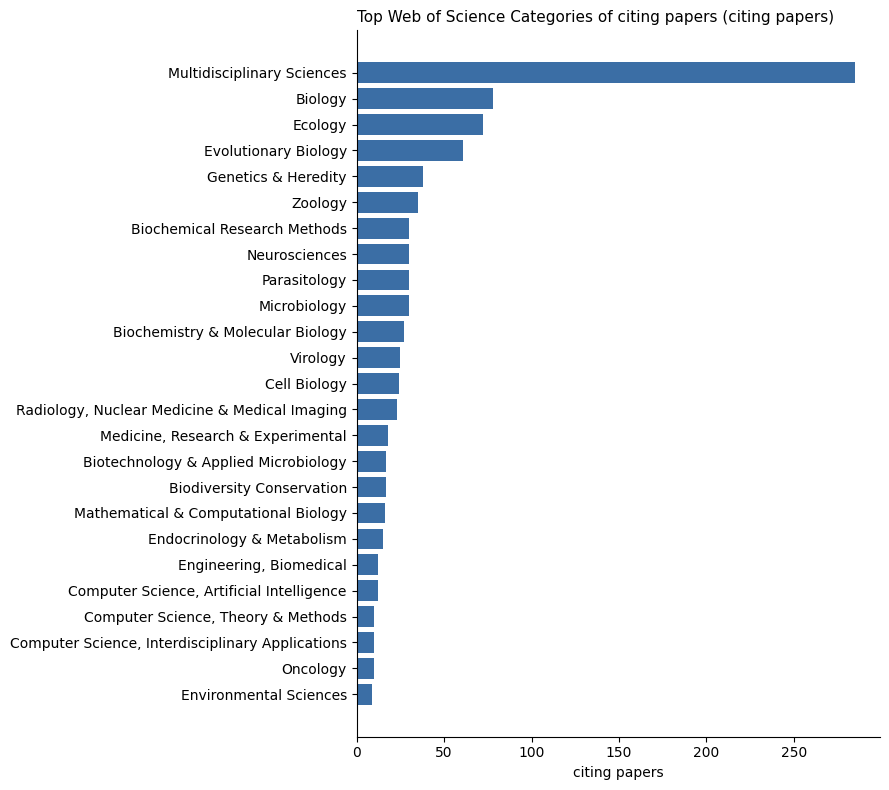

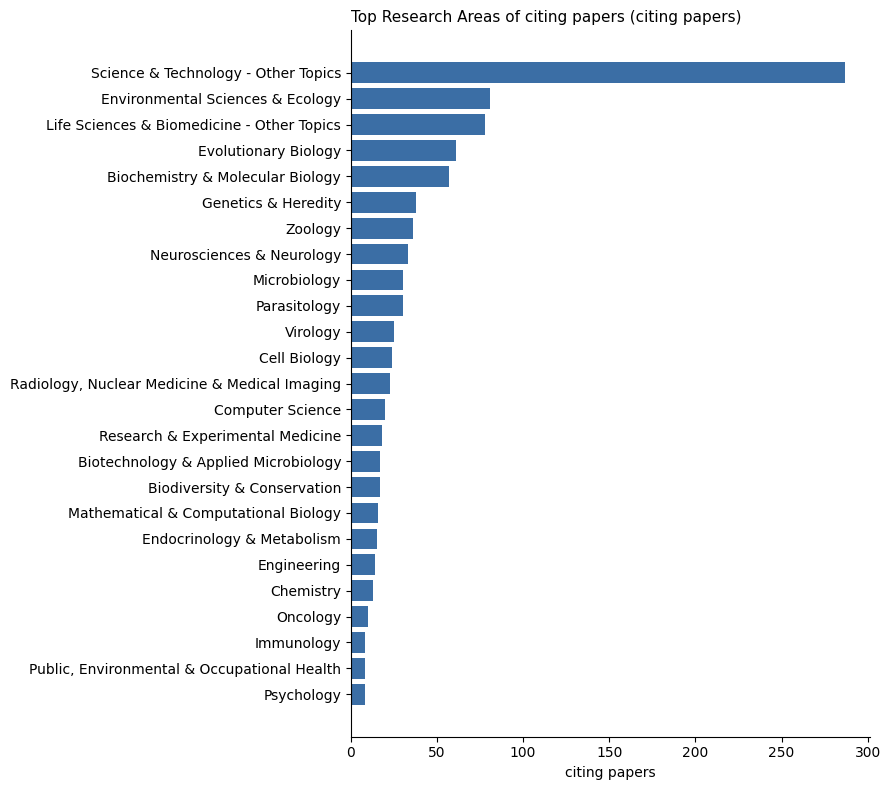

In [6]:
def explode_counts(df, col, label):
    s = Counter(unescape_text(x) for v in df[col] for x in set(split_vals(v)))
    t = pd.Series(s, name=UNIT_LABEL).rename_axis(label).reset_index().sort_values(UNIT_LABEL, ascending=False)
    t["share_%"] = (100 * t[UNIT_LABEL] / len(df)).round(1)
    return t.reset_index(drop=True)

CATS = explode_counts(UNIT_DF, "citing_wos_categories", "wos_category")
AREAS = explode_counts(UNIT_DF, "citing_research_areas", "research_area")
no_cat = sum(1 for v in UNIT_DF["citing_wos_categories"] if not split_vals(v))
print(f"{len(CATS)} WoS Categories | {len(AREAS)} Research Areas | {UNIT_LABEL} with no category: {no_cat:,}")
display(CATS.head(TOP_N))

def barh(t, col, title, fname):
    if plt is None:
        return
    top = t.head(TOP_N).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(top))))
    ax.barh(top[col], top[UNIT_LABEL], color="#3b6ea5")
    ax.set_xlabel(UNIT_LABEL); ax.set_title(title, loc="left", fontsize=11)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); fig.savefig(OUT_DIR / fname, dpi=200); plt.show()

barh(CATS, "wos_category", f"Top Web of Science Categories of citing papers ({UNIT_LABEL})", "wos_categories_top.png")
barh(AREAS, "research_area", f"Top Research Areas of citing papers ({UNIT_LABEL})", "research_areas_top.png")

## 7. Journals (sources) of the citing papers and their Web of Science Categories
One row per journal: how many citing papers it published, which of your DOIs they cited, and the journal's WoS Categories.
A long version (one row per journal × category) is saved too, for pivot tables.

In [7]:
g = UNIT_DF.assign(src=UNIT_DF.citing_source.replace("", "(no source)"))
g["src"] = g.src.map(unescape_text)
JOURNALS = (g.groupby("src")
            .agg(**{UNIT_LABEL: ("citing_doc_key", "size"),
                    "issn": ("citing_issn", lambda s: SEP.join(sorted({x for v in s for x in split_vals(v)}))),
                    "eissn": ("citing_eissn", lambda s: SEP.join(sorted({x for v in s for x in split_vals(v)}))),
                    "wos_categories": ("citing_wos_categories", lambda s: SEP.join(sorted({x for v in s for x in split_vals(v)}))),
                    "research_areas": ("citing_research_areas", lambda s: SEP.join(sorted({x for v in s for x in split_vals(v)}))),
                    })
            .reset_index().rename(columns={"src": "journal"})
            .sort_values(UNIT_LABEL, ascending=False).reset_index(drop=True))
tgt = edges.assign(src=edges.citing_source.replace("", "(no source)")).groupby("src").target_doi_normalized.nunique()
JOURNALS.insert(2, "target_dois_cited", JOURNALS.journal.map(tgt).fillna(0).astype(int))
print(f"{len(JOURNALS):,} journals/sources")
display(JOURNALS.head(TOP_N))

JOURNAL_CATEGORY_LONG = (JOURNALS[["journal", UNIT_LABEL, "wos_categories"]]
                         .assign(wos_category=lambda d: d.wos_categories.map(split_vals))
                         .explode("wos_category").drop(columns="wos_categories").reset_index(drop=True))

258 journals/sources


,journal,citing papers,target_dois_cited,issn,eissn,wos_categories,research_areas
0,PROCEEDINGS OF THE NATIONAL ACADEMY OF SCIENCES OF THE UNITED STATES OF AMERICA,82,93,0027-8424,1091-6490,Multidisciplinary Sciences,Science & Technology - Other Topics
1,NATURE COMMUNICATIONS,61,65,,2041-1723,Multidisciplinary Sciences,Science & Technology - Other Topics
2,SCIENCE,52,73,0036-8075,1095-9203,Multidisciplinary Sciences,Science & Technology - Other Topics
3,PROCEEDINGS OF THE ROYAL SOCIETY B-BIOLOGICAL SCIENCES,26,26,0962-8452,1471-2954,Biology | Ecology | Evolutionary Biology,Environmental Sciences & Ecology | Evolutionary Biology | Life Sciences & Bi...
4,PLOS PATHOGENS,23,25,1553-7366,1553-7374,Microbiology | Parasitology | Virology,Microbiology | Parasitology | Virology
5,NATURE,20,20,0028-0836,1476-4687,Multidisciplinary Sciences,Science & Technology - Other Topics
6,COMMUNICATIONS BIOLOGY,18,20,,2399-3642,Biology | Multidisciplinary Sciences,Life Sciences & Biomedicine - Other Topics | Science & Technology - Other To...
7,SCIENTIFIC DATA,15,18,,2052-4463,Multidisciplinary Sciences,Science & Technology - Other Topics
8,PLOS COMPUTATIONAL BIOLOGY,15,15,1553-734X,1553-7358,Biochemical Research Methods | Mathematical & Computational Biology,Biochemistry & Molecular Biology | Mathematical & Computational Biology
9,GENOME BIOLOGY,9,11,1474-760X,,Biotechnology & Applied Microbiology | Genetics & Heredity,Biotechnology & Applied Microbiology | Genetics & Heredity


## 8. Save maps and tables

In [8]:
MAPS = [(f, n_) for f, n_ in [(fig_world, "map_world_citing_countries"), (fig_us, "map_us_citing_states")] if f is not None]
saved = []
for f, n_ in MAPS:
    f.write_html(OUT_DIR / f"{n_}.html", include_plotlyjs="cdn")
    saved.append(f"{n_}.html")
if SAVE_PNG:
    try:
        for f, n_ in MAPS:
            f.write_image(OUT_DIR / f"{n_}.png", width=1400, height=800, scale=2)
            saved.append(f"{n_}.png")
    except Exception as e:
        print("PNG images not saved (install with:  %pip install kaleido  then re-run this cell). Reason:",
              str(e)[:150])

xlsx = OUT_DIR / "GREI_WoS_citing_countries_states_categories.xlsx"
for _t in (WORLD, US, CATS, AREAS, JOURNALS, JOURNAL_CATEGORY_LONG):
    for _c in _t.columns:
        if _t[_c].dtype == object or pd.api.types.is_string_dtype(_t[_c]):
            _t[_c] = _t[_c].map(unescape_text)
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    pd.DataFrame({"item": ["counting unit", "addresses used", "citing papers", "citation relationships",
                           "target DOIs cited", "source file"],
                  "value": [UNIT_LABEL, AUTHOR_SCOPE, len(docs), len(edges),
                            edges.target_doi_normalized.nunique(), str(MASTER_FILE)]}).to_excel(xw, sheet_name="about", index=False)
    WORLD.to_excel(xw, sheet_name="countries", index=False)
    pd.Series(names, name=UNIT_LABEL).rename_axis("wos_country_name").reset_index() \
      .assign(iso3=lambda d: d.wos_country_name.map(country_code)) \
      .sort_values(UNIT_LABEL, ascending=False).to_excel(xw, sheet_name="country_names_as_in_wos", index=False)
    US.to_excel(xw, sheet_name="us_states", index=False)
    CATS.to_excel(xw, sheet_name="wos_categories", index=False)
    AREAS.to_excel(xw, sheet_name="research_areas", index=False)
    JOURNALS.to_excel(xw, sheet_name="journals_with_categories", index=False)
    JOURNAL_CATEGORY_LONG.to_excel(xw, sheet_name="journal_x_category_long", index=False)
saved.append(xlsx.name)
print("Saved in", OUT_DIR)
for f in saved:
    print("  ", f)

PNG images not saved (install with:  %pip install kaleido  then re-run this cell). Reason: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"

Saved in C:\Users\keg827\Documents\Github_Repos\GREI_Data Citations Project\GREI_WoS_outputs\maps_and_categories
   map_world_citing_countries.html
   map_us_citing_states.html
   GREI_WoS_citing_countries_states_categories.xlsx


## 9. Summary statements (written from your results)
Plain-language summaries you can paste into a report: one overall summary, then one statement per map, chart and
table. All numbers come from the files in `GREI_WoS_outputs`, so re-running this notebook after more WoS exports
updates the text. Saved as `GREI_WoS_summary_statements.md` (opens in Word) and `.txt`.

In [12]:
import json
from datetime import date

def n(x): return f"{int(x):,}"
def p(a, b, d=1): return f"{100 * a / b:.{d}f}%" if b else "n/a"
def join(items):
    items = [str(i) for i in items if str(i)]
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1] if items else ""
def nice_country(c): return {"USA": "the United States", "GBR": "the United Kingdom", "CHN": "China"}.get(c, code_to_name.get(c, c))
def first_cap(t): return t[:1].upper() + t[1:]
def plural(k, word, many=None): return f"{n(k)} {word if k == 1 else (many or word + 's')}"
TYPE_LABEL = {"Dataset": ("dataset", "datasets"), "Software": ("software item", "software items"),
              "JournalArticle": ("journal article", "journal articles"), "Text": ("text item", "text items"),
              "Other": ("other output", "other outputs"), "Image": ("image", "images"),
              "ComputationalNotebook": ("computational notebook", "computational notebooks"),
              "Collection": ("collection", "collections"), "Preprint": ("preprint", "preprints"),
              "Book": ("book", "books"), "Report": ("report", "reports"), "Model": ("model", "models"),
              "StudyRegistration": ("study registration", "study registrations"),
              "InteractiveResource": ("interactive resource", "interactive resources"),
              "Audiovisual": ("audiovisual item", "audiovisual items"),
              "ConferenceProceeding": ("conference proceeding", "conference proceedings"),
              "(not specified)": ("output of unspecified type", "outputs of unspecified type")}
def tlabel(t, many=True):
    if t not in TYPE_LABEL:
        w = re.sub(r"(?<!^)(?=[A-Z])", " ", t).lower()
        return w + "s" if many else w
    return TYPE_LABEL[t][1 if many else 0]
_SMALL = {"OF", "AND", "THE", "IN", "FOR", "ON", "A", "AN", "AT", "TO", "&", "BY", "WITH", "FROM"}
_ACRO = {"PLOS", "BMC", "BMJ", "IEEE", "JAMA", "PNAS", "ACS", "RSC", "NPJ", "AIDS", "HIV", "PEERJ", "ELIFE", "AJR",
         "JCI", "EMBO", "FEBS", "MBIO", "ISME", "ACM", "SPIE", "IOP", "AIP", "JMIR", "NEJM", "USA", "UK", "II", "III", "IV"}
def journal_title(t):
    if not t or t != t.upper():
        return t
    out = []
    for i, w in enumerate(t.split()):
        core = w.strip(",:;()")
        if core in _ACRO:
            out.append({"PLOS": "PLOS", "PEERJ": "PeerJ", "ELIFE": "eLife", "MBIO": "mBio"}.get(core, core) + w[len(core):] if w.startswith(core) else w)
        elif i and core in _SMALL:
            out.append(w.lower())
        else:
            out.append(w[:1] + w[1:].lower())
    return " ".join(out)
def month_name(ym):
    try: return date(int(ym[:4]), int(ym[5:7]), 1).strftime("%B %Y")
    except Exception: return ym

OUT = BASE_DIR / "GREI_WoS_outputs"
merged_p, log_p, man_p = (OUT / "GREI-DataCite-NIHOnly_with_WoS_citations.csv", OUT / "GREI_WoS_processing_log.csv",
                          OUT / "GREI_WoS_archive_manifest.csv")
merged = pd.read_csv(merged_p, dtype=str, keep_default_na=False) if merged_p.exists() else None
log = pd.read_csv(log_p, dtype=str, keep_default_na=False) if log_p.exists() else None
man = pd.read_csv(man_p, dtype=str, keep_default_na=False) if man_p.exists() else None

N_docs, N_rel, N_cited = len(docs), len(edges), edges.target_doi_normalized.nunique()
per_doi = edges.groupby("target_doi_normalized").citing_doc_key.nunique()

# ---- scope: targets, WoS records searched, publication-date coverage --------------------------
N_targets = merged.id.replace("", np.nan).dropna().str.lower().nunique() if merged is not None else None
n_records = n_exports = None
if log is not None and len(log):
    done = log[log.status == "completed"].drop_duplicates("content_fingerprint", keep="last")
    n_exports = len(done)
    n_records = pd.to_numeric(done.records_examined, errors="coerce").sum()
cov_start = cov_end = None
partial_months = []
if man is not None and len(man):
    pm = man[pd.to_numeric(man.get("times_citation_completed", "0"), errors="coerce").fillna(0) > 0]
    monthly = Counter()
    for v in pm.get("records_by_year_month", []):
        try:
            for k, c in json.loads(v or "{}").items():
                if "year only" not in k: monthly[k] += int(c)
        except Exception:
            pass
    if monthly:
        typical = float(np.median(list(monthly.values())))
        core = sorted(k for k, c in monthly.items() if c >= max(100, 0.001 * typical))   # ignore stray records
        cov_start, cov_end = core[0], core[-1]
        tail = []
        for k in reversed(core):                           # thin months at the end of the period
            if monthly[k] < 0.25 * typical: tail.insert(0, k)
            else: break
        partial_months = tail

S = {}   # statement name -> text
SH = "share_%"

# ---- overall summary -------------------------------------------------------------------------------
p1 = []
scope = []
if n_records:
    scope.append(f"the cited-reference lists of {n(n_records)} Web of Science (WoS) publications")
    if cov_start:
        scope[-1] += f" published from {month_name(cov_start)} to {month_name(cov_end)}"
    if n_exports:
        scope[-1] += f" ({n_exports} TDM Studio exports)"
else:
    scope.append("the cited-reference lists of Web of Science (WoS) publications")
tgt_txt = f"{n(N_targets)} DOIs" if N_targets else "the DOIs"
p1.append(f"We searched {scope[0]} for {tgt_txt} of NIH-associated research outputs registered with DataCite "
          "by GREI-related repositories, matching DOIs exactly as they appear in each publication's reference list.")
cited_share = f" ({p(N_cited, N_targets)})" if N_targets else ""
p1.append(f"In total, {n(N_cited)} of these outputs{cited_share} were cited at least once, accounting for "
          f"{n(N_rel)} citations from {n(N_docs)} distinct WoS publications.")
once = (per_doi == 1).sum()
p1.append(f"Most cited outputs were cited by a single publication ({p(once, len(per_doi), 0)} of cited outputs); "
          f"the most cited was referenced by {plural(per_doi.max(), 'publication')}.")
if merged is not None and "target_title" in merged:
    top = merged.assign(w=pd.to_numeric(merged.wos_citing_documents, errors="coerce").fillna(0)).nlargest(3, "w")
    tops = [f'"{r.target_title[:110]}" ({n(r.w)})' for r in top.itertuples() if r.w > 0]
    if tops:
        p1.append(f"The most frequently cited were {join(tops)}.")

p2 = []
if merged is not None and "attributes_types_resourceTypeGeneral" in merged:
    m2 = merged.assign(w=pd.to_numeric(merged.wos_citing_documents, errors="coerce").fillna(0),
                       t=merged.attributes_types_resourceTypeGeneral.replace("", "(not specified)"))
    by_t = m2.groupby("t").agg(total=("w", "size"), cited=("w", lambda s: (s > 0).sum())).sort_values("cited", ascending=False)
    rel_t = edges[["target_doi_normalized"]].merge(m2[["id", "t"]].assign(target_doi_normalized=lambda d: d.id.str.lower()),
                        on="target_doi_normalized", how="left").t.value_counts()
    lead = by_t.index[0]
    p2.append(f"{first_cap(tlabel(lead))} were the most commonly cited type of output: {n(by_t.loc[lead, 'cited'])} of "
              f"{n(by_t.loc[lead, 'total'])} {tlabel(lead)} in the list ({p(by_t.loc[lead, 'cited'], by_t.loc[lead, 'total'])}) "
              f"were cited, accounting for {p(rel_t.get(lead, 0), N_rel, 0)} of all citations.")
    others = [f"{tlabel(t)} ({n(r.cited)} of {n(r.total)} cited)" for t, r in by_t.iloc[1:4].iterrows() if r.cited]
    if others:
        p2.append(f"Other cited types included {join(others)}.")
if merged is not None and "relationships_client_data_id" in merged:
    rep = edges[["target_doi_normalized"]].merge(merged[["id", "attributes_publisher"]].assign(target_doi_normalized=lambda d: d.id.str.lower()),
                      on="target_doi_normalized", how="left").attributes_publisher.replace("", "(unknown)").value_counts()
    if len(rep):
        p2.append(f"By repository, citations went most often to outputs published by "
                  f"{join([f'{k} ({n(v)})' for k, v in rep.head(4).items()])}.")

# ---- evidence for the US research enterprise ---------------------------------------------------------
FIFTY = US_STATES - {"DC", "PR", "GU", "VI"}
us_rows = [(us_states(raw)[0], raw) for raw in UNIT_DF[ADDR_COL]]
us_mask = [bool(st) or "USA" in str(raw) for st, raw in us_rows]
n_us = sum(us_mask)
states_50 = sorted({x for st, _ in us_rows for x in st} & FIFTY)
has_dc = "DC" in US.state.values
terrs = sorted(set(US.state) & {"PR", "GU", "VI"})
inst_papers, inst_states, inst_forms = Counter(), defaultdict(set), defaultdict(Counter)
paper_inst, paper_states = [], []
for raw in UNIT_DF[ADDR_COL]:
    seen, sts = set(), set()
    for a in str(raw).split(ADDR_SEP):
        a = re.sub(r"^\[[^\]]*\]\s*", "", a.strip())
        if not a.upper().endswith("USA"):
            continue
        form = a.split(",")[0].strip()
        key = form.upper()
        seen.add(key)
        inst_forms[key][form] += 1
        m = _STATE_ZIP.search(a) or _STATE_NOZIP.search(a)
        if m and m.group(1) in US_STATES:
            inst_states[key].add(m.group(1))
            sts.add(m.group(1))
    inst_papers.update(seen)
    paper_inst.append(sorted(inst_forms[k].most_common(1)[0][0] for k in seen))
    paper_states.append(sorted(sts))
us_inst = set(inst_papers)
top5 = list(US.state.head(5))
us_outside_top5 = sum(1 for st, _ in us_rows if st and not st <= set(top5))

NIH_RE = re.compile(
    r"National Institutes? of Health|\bNIH\b|National Cancer Institute|National Heart,? Lung,? (?:and|&) Blood|"
    r"National Institute (?:of|on) (?:Allergy|Mental Health|General Medical|Child Health|Drug Abuse|Alcohol|Diabetes|"
    r"Neurological|Environmental Health|Biomedical Imaging|Dental|Deafness|Nursing|Minority Health|Arthritis|Aging)|"
    r"National Human Genome|National Library of Medicine|National Center for Advancing Translational|National Eye Institute|"
    r"National Center for Complementary|\b(?:NCI|NHLBI|NIAID|NIMH|NIGMS|NICHD|NIDA|NIAAA|NIDDK|NINDS|NIEHS|NHGRI|NCATS|"
    r"NIBIB|NIDCR|NIDCD|NINR|NIMHD|NIAMS|NCCIH)\b|"
    r"\b(?:[RKUFPTDS]\d{2}|UL1|UM1|TL1|KL2|ZIA)\s?-?[A-Z]{2}\s?\d{5,6}\b")
FED_RE = re.compile(
    r"(?<!Swiss )(?<!Natural )National Science Foundation(?! of China)|\bNSF\b|"
    r"(?:United States|US|U\.S\.) Department of (?:Health (?:&|and) Human Services|Energy|Defense|Agriculture|"
    r"Veterans Affairs|Commerce|the Interior|Education|Homeland Security|Transportation)|"
    r"Department of Energy|Department of Defense|\bDOD\b|\bNASA\b|"
    r"National Aeronautics and Space|\bUSDA\b|Veterans Affairs|Centers for Disease Control|Food and Drug Administration|"
    r"Agency for Healthcare Research|National Oceanic and Atmospheric|\bNOAA\b|Geological Survey|"
    r"Environmental Protection Agency|Department of Health (?:&|and) Human Services|\bHHS\b")
fund_cols = [c for c in ["citing_funding_agencies_original", "citing_funding_agencies_preferred",
                         "citing_funding_agencies_parent", "citing_grant_numbers", "citing_funding_text"] if c in UNIT_DF]
fund_txt = UNIT_DF[fund_cols].agg(" ".join, axis=1) if fund_cols else pd.Series([""] * len(UNIT_DF))
nih_mask = fund_txt.str.contains(NIH_RE)
fed_mask = nih_mask | fund_txt.str.contains(FED_RE)
has_fund = fund_txt.str.strip().ne("")

pus = []
if n_us:
    breadth = "broad" if len(states_50) >= 25 else ("geographically varied" if len(states_50) >= 10 else "")
    where = f"{len(states_50)} of the 50 states" + (" and the District of Columbia" if has_dc else "") + \
            (f", plus {join([STATE_NAMES[t] for t in terrs])}" if terrs else "")
    pus.append(f"For the US research enterprise, these citations document {breadth + ' ' if breadth else ''}domestic reuse "
               "of NIH-associated research outputs shared through generalist repositories.")
    pus.append(f"{n(n_us)} of the {n(len(UNIT_DF))} citing publications ({p(n_us, len(UNIT_DF), 0)}) had at least one author at a "
               f"US institution, spanning about {n(len(us_inst))} distinct US institutions (as named in WoS addresses) in {where}.")
    if len(US) > 5 and us_outside_top5:
        pus.append(f"Reuse was not confined to a few research centres: {p(us_outside_top5, n_us, 0)} of US-authored citing "
                   f"publications included authors outside the five most active states "
                   f"({join([STATE_NAMES.get(x, x) for x in top5])}).")
if has_fund.any():
    pus.append(f"{n(nih_mask.sum())} citing publications ({p(nih_mask.sum(), len(UNIT_DF), 0)}) acknowledge NIH support and "
               f"{n(fed_mask.sum())} ({p(fed_mask.sum(), len(UNIT_DF), 0)}) at least one US federal agency, indicating that "
               "these outputs are being reused within federally funded research.")
n_intl = len(UNIT_DF) - n_us
if n_us and n_intl:
    pus.append(f"At the same time, {n(n_intl)} citing publications ({p(n_intl, len(UNIT_DF), 0)}) had no US-based author, "
               "showing that outputs from US-funded research deposited in these repositories also reach researchers "
               "internationally.")

p3 = []
if len(WORLD):
    top3 = [f"{nice_country(r.iso3)} ({p(r[UNIT_LABEL], len(UNIT_DF), 0)}{' of citing publications' if i == 0 else ''})"
            for i, (_, r) in enumerate(WORLD.head(4).iterrows())]
    p3.append(f"The citing publications had authors in {plural(len(WORLD), 'country', 'countries')}, led by {join(top3)}.")
if len(US):
    p3.append(f"Within the United States the most active states were "
              f"{join([f'{r.state_name} ({n(r[UNIT_LABEL])})' for _, r in US.head(3).iterrows()])}.")
if len(CATS):
    p3.append(f"The publications spanned {plural(len(CATS), 'Web of Science Category', 'Web of Science Categories')}; the most common were "
              f"{join([f'{r.wos_category} ({p(r[UNIT_LABEL], len(UNIT_DF), 0)})' for _, r in CATS.head(3).iterrows()])}, "
              f"and they appeared in {plural(len(JOURNALS[JOURNALS.journal != '(no source)']), 'journal or other source', 'journals and other sources')}.")

p4 = ["Counts are of distinct citing publications unless stated otherwise: a publication citing several of the outputs, "
      "or listing authors in several countries or categories, is counted once in each. "
      "Only citations that include the output's DOI in a WoS reference list can be detected, so data citations given "
      "without a DOI, in data-availability statements only, or in publications outside WoS are not counted; these figures "
      "are therefore conservative, and differ from DataCite's own citation counts, which draw on other sources."]
if partial_months:
    p4.append(f"Coverage of the most recent period is incomplete: from {month_name(partial_months[0])} onward the TDM Studio "
              "data contain far fewer WoS publications per month than earlier months, and recently published outputs have "
              "had little time to accumulate citations.")
S["Overall summary"] = "\n\n".join(" ".join(x) for x in (p1, pus, p2, p3, p4) if x)

# ---- per-figure statements --------------------------------------------------------------------------
if len(WORLD):
    half = int((WORLD[UNIT_LABEL].cumsum() >= WORLD[UNIT_LABEL].sum() / 2).idxmax()) + 1
    w = WORLD
    S["World map — citing countries"] = (
        f"Authors of the {n(len(UNIT_DF))} WoS {UNIT_LABEL} were affiliated with institutions in {plural(len(w), 'country', 'countries')}. "
        f"{first_cap(nice_country(w.iso3[0]))} appeared most often ({n(w[UNIT_LABEL][0])} {UNIT_LABEL}, "
        f"{w['share_%'][0]}%), followed by {join([f'{nice_country(r.iso3)} ({r[UNIT_LABEL]:,}; {r[SH]}%)' for _, r in w.iloc[1:5].iterrows()])}. "
        f"{'The top country accounts' if half == 1 else f'The top {half} countries account'} for at least half of all country appearances. "
        + f"Each publication is counted once for every country in its author addresses: a paper with three authors in "
        "Germany counts once for Germany, and a paper with authors in Germany and France counts once for each, so "
        "percentages sum to more than 100%. England, Scotland, Wales and Northern Ireland are combined as the United Kingdom"
        + ("; shading uses a logarithmic scale." if LOG_COLOR_SCALE else "."))
if len(US):
    us_n = us_papers
    S["US map — citing states"] = (
        f"{n(us_n)} of the {n(len(UNIT_DF))} {UNIT_LABEL} ({p(us_n, len(UNIT_DF), 0)}) included at least one author at a US "
        f"institution. These authors were based in {len(states_50)} of the 50 states"
        + (" and the District of Columbia" if has_dc else "")
        + (f", plus {join([STATE_NAMES[t] for t in terrs])}" if terrs else "")
        + f", with the most in {join([f'{r.state_name} ({n(r[UNIT_LABEL])})' for _, r in US.head(5).iterrows()])}. "
        "Each publication is counted once for every state in its author addresses: two co-authors in the same state count "
        "once for that state, and a paper with authors in two states counts once for each"
        + ("; shading uses a logarithmic scale" if LOG_COLOR_SCALE else "")
        + ("; territories are included in the counts but not shaded on the map." if terrs else "."))
if len(CATS):
    k10 = CATS.head(10)
    S["Web of Science Categories chart"] = (
        f"The citing publications were classified into {plural(len(CATS), 'Web of Science Category', 'Web of Science Categories')}, assigned through the "
        f"journals in which they appeared. The most frequent were {join([f'{r.wos_category} ({n(r[UNIT_LABEL])}; {r[SH]}%)' for _, r in CATS.head(5).iterrows()])}. "
        "A publication in a journal with several categories is counted in each, so percentages sum to more than 100%.")
if len(AREAS):
    S["Research Areas chart"] = (
        f"Grouped into broader WoS Research Areas, the citing publications covered {plural(len(AREAS), 'area')}, led by "
        f"{join([f'{r.research_area} ({p(r[UNIT_LABEL], len(UNIT_DF), 0)})' for _, r in AREAS.head(4).iterrows()])}.")
if len(JOURNALS):
    j = JOURNALS[JOURNALS.journal != "(no source)"]
    top10 = j.head(10)[UNIT_LABEL].sum()
    S["Journals table"] = (
        f"Citations came from {plural(len(j), 'journal or other source', 'journals and other sources')}. The most frequent were "
        f"{join([f'{journal_title(r.journal)} ({n(r[UNIT_LABEL])})' for _, r in j.head(5).iterrows()])}; "
        f"together the ten most frequent sources account for {p(top10, len(UNIT_DF), 0)} of {UNIT_LABEL}, indicating "
        f"{'a broad spread across many venues' if top10 < 0.5 * len(UNIT_DF) else 'a concentration in a small number of venues'}.")

S = {k: unescape_text(v) for k, v in S.items()}
md_text = "# GREI outputs cited in Web of Science — summary statements\n\n" + \
          "\n\n".join(f"## {k}\n\n{v}" for k, v in S.items()) + "\n"
(OUT_DIR / "GREI_WoS_summary_statements.md").write_text(md_text, encoding="utf-8")
(OUT_DIR / "GREI_WoS_summary_statements.txt").write_text(md_text.replace("## ", "").replace("# ", ""), encoding="utf-8")
try:
    from IPython.display import Markdown
    display(Markdown(md_text))
except Exception:
    print(md_text)
print("Saved:", OUT_DIR / "GREI_WoS_summary_statements.md")

# ---- backup of the evidence behind the US-infrastructure paragraph -------------------------------------
US_INSTITUTIONS = pd.DataFrame([{
    "institution (as written in WoS addresses)": inst_forms[k].most_common(1)[0][0],
    "states": SEP.join(sorted(inst_states[k])),
    UNIT_LABEL: c,
    "name variants seen": SEP.join(f for f, _ in inst_forms[k].most_common()[1:]),
} for k, c in inst_papers.items()]).sort_values(UNIT_LABEL, ascending=False).reset_index(drop=True) if inst_papers \
    else pd.DataFrame(columns=["institution (as written in WoS addresses)", "states", UNIT_LABEL, "name variants seen"])

def matched_names(text, rx):
    return SEP.join(sorted({m.group(0).strip() for m in rx.finditer(text)}))

EVIDENCE = pd.DataFrame({
    "citing_wos_ut": UNIT_DF.get("citing_wos_ut", ""),
    "citing_doi": UNIT_DF.get("citing_doi", ""),
    "citing_title": UNIT_DF.get("citing_title", ""),
    "citing_source": UNIT_DF.get("citing_source", ""),
    "citing_year": UNIT_DF.get("citing_year", ""),
    "has_us_author": us_mask,
    "us_states": [SEP.join(x) for x in paper_states],
    "us_institutions": [SEP.join(x) for x in paper_inst],
    "countries": UNIT_DF[COUNTRY_COL],
    "acknowledges_nih": nih_mask.values,
    "nih_evidence (matched text)": [matched_names(t, NIH_RE) for t in fund_txt],
    "acknowledges_us_federal_agency": fed_mask.values,
    "federal_evidence (matched text)": [SEP.join(x for x in (matched_names(t, NIH_RE), matched_names(t, FED_RE)) if x)
                                        for t in fund_txt],      # NIH counts as a US federal agency
    "funding_agencies_preferred": UNIT_DF.get("citing_funding_agencies_preferred", ""),
}).reset_index(drop=True)
if COUNT_UNIT == "citations":
    EVIDENCE.insert(0, "target_doi_normalized", UNIT_DF.target_doi_normalized.values)

ev_xlsx = OUT_DIR / "GREI_WoS_us_institutions_and_funding.xlsx"
about = pd.DataFrame({"item": ["what this is", "institutions", "NIH / federal funding", "counting unit", "source file"],
                      "value": ["Evidence behind the 'US research enterprise' paragraph of the summary statements.",
                                "First part of each US author address as written in WoS (not standardised: one "
                                "institution can appear under several names, e.g. 'Harvard Med Sch' and 'Harvard Univ').",
                                "Detected from funder names, NIH institute names and NIH grant-number patterns in the "
                                "funding information of each citing paper; the matched text is shown for checking.",
                                UNIT_LABEL, str(MASTER_FILE)]})
with pd.ExcelWriter(ev_xlsx, engine="openpyxl") as xw:
    about.to_excel(xw, sheet_name="about", index=False)
    US_INSTITUTIONS.to_excel(xw, sheet_name="us_institutions", index=False)
    EVIDENCE.to_excel(xw, sheet_name="citing_paper_evidence", index=False)
US_INSTITUTIONS.to_csv(OUT_DIR / "GREI_WoS_us_institutions.csv", index=False, encoding="utf-8")
EVIDENCE.to_csv(OUT_DIR / "GREI_WoS_citing_paper_us_and_funding_evidence.csv", index=False, encoding="utf-8")
print(f"Saved: {ev_xlsx.name} ({len(US_INSTITUTIONS):,} US institutions; {len(EVIDENCE):,} {UNIT_LABEL}) "
      "+ CSV copies")
display(US_INSTITUTIONS.head(TOP_N))

# GREI outputs cited in Web of Science — summary statements

## Overall summary

We searched the cited-reference lists of 14,982,019 Web of Science (WoS) publications published from January 2022 to December 2026 (15 TDM Studio exports) for 18,394 DOIs of NIH-associated research outputs registered with DataCite by GREI-related repositories, matching DOIs exactly as they appear in each publication's reference list. In total, 694 of these outputs (3.8%) were cited at least once, accounting for 807 citations from 728 distinct WoS publications. Most cited outputs were cited by a single publication (95% of cited outputs); the most cited was referenced by 30 publications. The most frequently cited were "Mammal Diversity Database" (30), "Mammal Diversity Database" (16) and "mrirecon/bart: version 1.0.00" (14).

For the US research enterprise, these citations document broad domestic reuse of NIH-associated research outputs shared through generalist repositories. 640 of the 728 citing publications (88%) had at least one author at a US institution, spanning about 675 distinct US institutions (as named in WoS addresses) in 50 of the 50 states and the District of Columbia, plus Puerto Rico. Reuse was not confined to a few research centres: 72% of US-authored citing publications included authors outside the five most active states (California, Maryland, Massachusetts, New York and Pennsylvania). 582 citing publications (80%) acknowledge NIH support and 605 (83%) at least one US federal agency, indicating that these outputs are being reused within federally funded research. At the same time, 88 citing publications (12%) had no US-based author, showing that outputs from US-funded research deposited in these repositories also reach researchers internationally.

Datasets were the most commonly cited type of output: 547 of 11,024 datasets in the list (5.0%) were cited, accounting for 78% of all citations. Other cited types included software items (59 of 1,299 cited), journal articles (21 of 1,221 cited) and text items (17 of 1,249 cited). By repository, citations went most often to outputs published by Dryad (344), Zenodo (322), figshare (96) and Mendeley Data (35).

The citing publications had authors in 97 countries, led by the United States (88% of citing publications), Germany (9%), the United Kingdom (8%) and Canada (5%). Within the United States the most active states were California (189), Maryland (111) and Massachusetts (111). The publications spanned 107 Web of Science Categories; the most common were Multidisciplinary Sciences (39%), Biology (11%) and Ecology (10%), and they appeared in 258 journals and other sources.

Counts are of distinct citing publications unless stated otherwise: a publication citing several of the outputs, or listing authors in several countries or categories, is counted once in each. Only citations that include the output's DOI in a WoS reference list can be detected, so data citations given without a DOI, in data-availability statements only, or in publications outside WoS are not counted; these figures are therefore conservative, and differ from DataCite's own citation counts, which draw on other sources. Coverage of the most recent period is incomplete: from February 2026 onward the TDM Studio data contain far fewer WoS publications per month than earlier months, and recently published outputs have had little time to accumulate citations.

## World map — citing countries

Authors of the 728 WoS citing papers were affiliated with institutions in 97 countries. The United States appeared most often (640 citing papers, 87.9%), followed by Germany (65; 8.9%), the United Kingdom (55; 7.6%), Canada (39; 5.4%) and China (37; 5.1%). The top country accounts for at least half of all country appearances. Each publication is counted once for every country in its author addresses: a paper with three authors in Germany counts once for Germany, and a paper with authors in Germany and France counts once for each, so percentages sum to more than 100%. England, Scotland, Wales and Northern Ireland are combined as the United Kingdom; shading uses a logarithmic scale.

## US map — citing states

640 of the 728 citing papers (88%) included at least one author at a US institution. These authors were based in 50 of the 50 states and the District of Columbia, plus Puerto Rico, with the most in California (189), Maryland (111), Massachusetts (111), New York (101) and Pennsylvania (83). Each publication is counted once for every state in its author addresses: two co-authors in the same state count once for that state, and a paper with authors in two states counts once for each; shading uses a logarithmic scale; territories are included in the counts but not shaded on the map.

## Web of Science Categories chart

The citing publications were classified into 107 Web of Science Categories, assigned through the journals in which they appeared. The most frequent were Multidisciplinary Sciences (285; 39.1%), Biology (78; 10.7%), Ecology (72; 9.9%), Evolutionary Biology (61; 8.4%) and Genetics & Heredity (38; 5.2%). A publication in a journal with several categories is counted in each, so percentages sum to more than 100%.

## Research Areas chart

Grouped into broader WoS Research Areas, the citing publications covered 79 areas, led by Science & Technology - Other Topics (39%), Environmental Sciences & Ecology (11%), Life Sciences & Biomedicine - Other Topics (11%) and Evolutionary Biology (8%).

## Journals table

Citations came from 258 journals and other sources. The most frequent were Proceedings of the National Academy of Sciences of the United States of America (82), Nature Communications (61), Science (52), Proceedings of the Royal Society B-biological Sciences (26) and PLOS Pathogens (23); together the ten most frequent sources account for 44% of citing papers, indicating a broad spread across many venues.


Saved: C:\Users\keg827\Documents\Github_Repos\GREI_Data Citations Project\GREI_WoS_outputs\maps_and_categories\GREI_WoS_summary_statements.md
Saved: GREI_WoS_us_institutions_and_funding.xlsx (675 US institutions; 728 citing papers) + CSV copies


,institution (as written in WoS addresses),states,citing papers,name variants seen
0,Harvard Med Sch,MA,53,
1,Stanford Univ,CA,51,
2,Univ Washington,WA,41,
3,Univ Penn,PA,37,
4,Duke Univ,NC,26,
5,Univ Calif Berkeley,CA,25,
6,Univ Calif San Francisco,CA,25,
7,Columbia Univ,NY,25,
8,Yale Univ,CT,24,
9,Univ Calif San Diego,CA,23,


## 10. Package for collaborators (Keith Herzog and Veronica Hoyo)
Collects the shareable results into one folder, **`GREI_WoS_outputs/GREI_WoS_results_package/`**, and zips it:

| File | Contents |
|---|---|
| `1_GREI_WoS_citations_by_DOI.xlsx` | one row per target DOI (all of them), with WoS times cited |
| `2_GREI_WoS_citation_list.xlsx` | one row per target DOI × citing WoS paper, with the citing paper's details |
| `3_GREI_WoS_summary_tables.xlsx` | complete tables (citing papers, resource types, repositories, years, document types, countries, US states, US institutions, organizations, funders, WoS Categories, Research Areas, journals) |
| `4_GREI_WoS_data_dictionary.xlsx` | every file, tab and column described |
| `maps_and_charts/` | world and US maps (HTML; PNG if kaleido is installed) and category charts |
| `GREI_WoS_summary_statements.md / .txt` | the written summaries |

`DOI_FILE_ALL_ORIGINAL_COLUMNS = False` keeps the DOI file small (identifying columns + WoS counts; they can join back to
their own file on `id`). Set it to `True` to include every original column (the file gets much larger).

In [13]:
import shutil, zipfile as _zf
DOI_FILE_ALL_ORIGINAL_COLUMNS = False
PKG = OUT / "GREI_WoS_results_package"
if PKG.exists():
    shutil.rmtree(PKG)
(PKG / "maps_and_charts").mkdir(parents=True)

# ---------------------------------------------------------------- helpers
from openpyxl.utils import get_column_letter
from openpyxl.styles import Font, Alignment, PatternFill
_ILLEGAL = re.compile(r"[\000-\010\013\014\016-\037]")
TRUNCATED = Counter()
def _safe(v, where):
    if isinstance(v, str):
        v = _ILLEGAL.sub("", unescape_text(v))
        if len(v) > 32000:
            TRUNCATED[where] += 1
            v = v[:32000] + " …[shortened for Excel]"
    return v

WRITTEN = []          # (file, sheet, DataFrame) for the data dictionary
def write_book(fname, sheets, intro=None):
    path = PKG / fname
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        if intro is not None:
            intro.to_excel(xw, sheet_name="README", index=False)
        for name, df in sheets.items():
            out = df.copy()
            for c in out.columns:
                if out[c].dtype == object or pd.api.types.is_string_dtype(out[c]):
                    out[c] = out[c].map(lambda v, c=c: _safe(v, f"{fname} / {name}"))
            out.to_excel(xw, sheet_name=name[:31], index=False)
            WRITTEN.append((fname, name[:31], df))
        for ws in xw.book.worksheets:
            ws.freeze_panes = "A2"
            if ws.max_row > 1:
                ws.auto_filter.ref = ws.dimensions
            for cell in ws[1]:
                cell.font = Font(bold=True)
                cell.fill = PatternFill("solid", fgColor="DDE6F0")
            for i, col in enumerate(ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)), 1):
                width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
                ws.column_dimensions[get_column_letter(i)].width = min(max(10, width + 2), 60)
    return path

def count_multi(df, col, label, unit=UNIT_LABEL):
    c = Counter(unescape_text(x) for v in df[col] for x in set(split_vals(v))) if col in df else Counter()
    t = pd.Series(c, name=unit).rename_axis(label).reset_index()
    if len(t):
        t["share_of_citing_papers_%"] = (100 * t[unit] / len(df)).round(1)
        t = t.sort_values([unit, label], ascending=[False, True])
    return t.reset_index(drop=True)

# ---------------------------------------------------------------- 1. DOI-level file
m1 = merged.copy() if merged is not None else pd.DataFrame()
for c in m1.columns:
    if c in ("target_title", "attributes_titles", "attributes_publisher"):
        m1[c] = m1[c].map(unescape_text)
WOS_COLS = ["wos_citing_documents", "wos_unique_citing_dois", "wos_earliest_citing_year", "wos_latest_citing_year",
            "wos_unique_citing_countries", "wos_unique_citing_organizations", "wos_citing_countries"]
ID_COLS = ["id", "attributes_doi", "target_title", "attributes_publisher", "relationships_client_data_id",
           "attributes_types_resourceTypeGeneral", "attributes_types_resourceType", "attributes_publicationYear",
           "attributes_url", "attributes_citationCount", "attributes_viewCount", "attributes_downloadCount"]
if len(m1):
    if "source_excel_row" in m1:
        m1 = m1.rename(columns={"source_excel_row": "source_row_in_original_file"})
    orig_order = [c for c in m1.columns if c not in WOS_COLS]
    keep = (["source_row_in_original_file"] if "source_row_in_original_file" in m1 else []) + \
           ([c for c in orig_order if c not in ("source_row_in_original_file", "target_doi_normalized",
                                                 "target_doi_normalization_status", "attributes_doi_normalized",
                                                 "id_vs_attributes_doi")]
            if DOI_FILE_ALL_ORIGINAL_COLUMNS else [c for c in ID_COLS if c in m1]) + [c for c in WOS_COLS if c in m1]
    DOI_TABLE = m1[keep].copy()
    for c in WOS_COLS[:2] + WOS_COLS[4:6]:
        if c in DOI_TABLE:
            DOI_TABLE[c] = pd.to_numeric(DOI_TABLE[c], errors="coerce").fillna(0).astype(int)
    DOI_TABLE = DOI_TABLE.sort_values(["wos_citing_documents", "id"], ascending=[False, True]).reset_index(drop=True)
else:
    DOI_TABLE = pd.DataFrame()

# ---------------------------------------------------------------- 2. citation list (DOI x citing paper)
CIT_COLS = [("target_doi_normalized", "target_doi"), ("target_title", "target_title"),
            ("attributes_publisher", "target_publisher"), ("relationships_client_data_id", "target_repository_client_id"),
            ("attributes_types_resourceTypeGeneral", "target_resource_type_general"),
            ("attributes_types_resourceType", "target_resource_type"), ("attributes_publicationYear", "target_publication_year"),
            ("citing_wos_ut", "citing_wos_ut"), ("citing_doi", "citing_doi"), ("citing_title", "citing_title"),
            ("citing_source", "citing_source"), ("citing_issn", "citing_issn"), ("citing_eissn", "citing_eissn"),
            ("citing_year", "citing_year"), ("citing_publication_date", "citing_publication_date"),
            ("citing_document_type", "citing_document_type"), ("citing_authors", "citing_authors"),
            ("citing_corresponding_authors", "citing_corresponding_authors"),
            ("citing_corresponding_address_raw", "citing_corresponding_address"),
            ("citing_corresponding_countries", "citing_corresponding_countries"),
            ("citing_affiliations_raw", "citing_author_addresses"), ("citing_organizations", "citing_organizations"),
            ("citing_cities", "citing_cities"), ("citing_regions", "citing_states_regions"),
            ("citing_countries", "citing_countries"), ("citing_wos_categories", "citing_wos_categories"),
            ("citing_research_areas", "citing_research_areas"), ("citing_author_keywords", "citing_author_keywords"),
            ("citing_keywords_plus", "citing_keywords_plus"), ("citing_abstract", "citing_abstract"),
            ("citing_funding_agencies_original", "citing_funders_original_names"),
            ("citing_funding_agencies_preferred", "citing_funders_preferred_names"),
            ("citing_grant_numbers", "citing_grant_numbers"), ("citing_funding_text", "citing_funding_acknowledgment"),
            ("citing_reference_count", "citing_reference_count"),
            ("n_mentions_in_reference_list", "times_target_listed_in_reference_list"),
            ("matched_cited_reference_doi", "matched_reference_doi_as_written"),
            ("matched_cited_reference_raw", "matched_reference_text"),
            ("archive_dataset_name", "wos_export_dataset"), ("citing_proquest_goid", "citing_proquest_goid")]
cit = edges.copy()
CITATIONS = pd.DataFrame({new: cit[old] if old in cit else "" for old, new in CIT_COLS})
CITATIONS = CITATIONS.sort_values(["target_doi", "citing_year", "citing_wos_ut"]).reset_index(drop=True)

# ---------------------------------------------------------------- 3. full summary tables
cp = docs.copy()
n_t = edges.groupby("citing_doc_key").target_doi_normalized.agg(["nunique", lambda s: SEP.join(sorted(set(s)))])
n_t.columns = ["n_target_dois_cited", "target_dois_cited"]
ev_by = EVIDENCE.copy() if COUNT_UNIT == "documents" else None
_col = lambda c: cp[c] if c in cp else pd.Series([""] * len(cp), index=cp.index)
CITING_PAPERS = pd.DataFrame({
    "citing_wos_ut": _col("citing_wos_ut"), "citing_doi": _col("citing_doi"), "citing_title": _col("citing_title"),
    "citing_source": _col("citing_source"), "citing_year": _col("citing_year"),
    "citing_document_type": _col("citing_document_type"), "citing_countries": _col("citing_countries"),
    "n_target_dois_cited": cp.citing_doc_key.map(n_t.n_target_dois_cited).astype(int),
    "target_dois_cited": cp.citing_doc_key.map(n_t.target_dois_cited),
}).reset_index(drop=True)
if ev_by is not None and len(ev_by) == len(CITING_PAPERS):
    for c in ["has_us_author", "us_states", "us_institutions", "acknowledges_nih", "acknowledges_us_federal_agency",
              "federal_evidence (matched text)"]:
        CITING_PAPERS[c] = ev_by[c].values
CITING_PAPERS = CITING_PAPERS.sort_values(["n_target_dois_cited", "citing_year"], ascending=[False, False]).reset_index(drop=True)

def target_breakdown(col, label):
    if merged is None or col not in merged:
        return pd.DataFrame()
    m = merged.assign(w=pd.to_numeric(merged.wos_citing_documents, errors="coerce").fillna(0),
                      k=merged[col].map(unescape_text).replace("", "(not specified)"),
                      d=merged.id.str.lower())
    e = edges[["target_doi_normalized", "citing_doc_key"]].merge(m[["d", "k"]], left_on="target_doi_normalized",
                                                                 right_on="d", how="left")
    t = m.groupby("k").agg(dois_in_list=("w", "size"), dois_cited=("w", lambda s: int((s > 0).sum())))
    t["share_cited_%"] = (100 * t.dois_cited / t.dois_in_list).round(1)
    t["citations"] = e.groupby("k").size().reindex(t.index).fillna(0).astype(int)
    t["citing_papers"] = e.groupby("k").citing_doc_key.nunique().reindex(t.index).fillna(0).astype(int)
    return t.sort_values(["citations", "dois_in_list"], ascending=False).rename_axis(label).reset_index()

RESOURCE_TYPES = target_breakdown("attributes_types_resourceTypeGeneral", "resource_type_general")
REPOSITORIES = target_breakdown("attributes_publisher", "publisher")
CLIENTS = target_breakdown("relationships_client_data_id", "datacite_client_id")
_yr = edges["citing_year"] if "citing_year" in edges else pd.Series("", index=edges.index)
YEARS = (edges.assign(_y=_yr.replace("", "(unknown)")).groupby("_y")
         .agg(citing_papers=("citing_doc_key", "nunique"), citations=("citing_doc_key", "size"),
              target_dois_cited=("target_doi_normalized", "nunique"))
         .rename_axis("citing_publication_year").reset_index().sort_values("citing_publication_year"))
DOCTYPES = count_multi(docs, "citing_document_type", "citing_document_type", "citing_papers")
ORGS = count_multi(docs, "citing_organizations", "organization_wos_preferred_name", "citing_papers")
FUNDERS = count_multi(docs, "citing_funding_agencies_preferred", "funder_wos_preferred_name", "citing_papers")
FUNDERS_ORIG = count_multi(docs, "citing_funding_agencies_original", "funder_name_as_acknowledged", "citing_papers")
COUNTRIES_FULL = WORLD.rename(columns={"share_%": "share_of_citing_papers_%"})
COUNTRY_NAMES = pd.Series(names, name=UNIT_LABEL).rename_axis("country_name_in_wos").reset_index() \
    .assign(iso3=lambda d: d.country_name_in_wos.map(country_code)).sort_values(UNIT_LABEL, ascending=False)
STATES_FULL = US.assign(share_of_us_citing_papers_pct=lambda d: (100 * d[UNIT_LABEL] / max(us_papers, 1)).round(1))
CATS_FULL = CATS.rename(columns={"share_%": "share_of_citing_papers_%"})
AREAS_FULL = AREAS.rename(columns={"share_%": "share_of_citing_papers_%"})

about_rows = [("Prepared", str(date.today())),
              ("What this is", "WoS publications whose reference lists cite DOIs from GREI-DataCite-NIHOnly.csv"),
              ("Target DOIs in the list", n(N_targets) if N_targets else ""),
              ("Target DOIs cited at least once", n(N_cited)),
              ("Citations (target DOI x citing paper)", n(N_rel)),
              ("Distinct citing WoS papers", n(N_docs)),
              ("WoS publications searched", n(n_records) if n_records else ""),
              ("Publication dates covered", f"{month_name(cov_start)} to {month_name(cov_end)}" if cov_start else ""),
              ("Counting rule", "Tables count citing papers once per country / state / institution / category / funder, "
                                "however many authors or entries of that kind the paper has (whole counting)."),
              ("Matching rule", "Exact DOI match (after removing https://doi.org/, doi: and case differences) in the "
                                "WoS cited-reference list; the citing paper's own DOI is never used."),
              ("Multi-value separator", f"'{SEP.strip()}' between values; '{ADDR_SEP.strip()}' between full addresses")]
ABOUT = pd.DataFrame(about_rows, columns=["item", "value"])

TABLES = {"citing_papers": CITING_PAPERS, "resource_types": RESOURCE_TYPES, "repositories_publishers": REPOSITORIES,
          "repositories_datacite_client": CLIENTS, "citing_years": YEARS, "citing_document_types": DOCTYPES,
          "countries": COUNTRIES_FULL, "country_names_in_wos": COUNTRY_NAMES, "us_states": STATES_FULL,
          "us_institutions": US_INSTITUTIONS, "organizations_worldwide": ORGS, "funders_preferred_names": FUNDERS,
          "funders_original_names": FUNDERS_ORIG, "wos_categories": CATS_FULL, "research_areas": AREAS_FULL,
          "journals": JOURNALS, "journal_x_category": JOURNAL_CATEGORY_LONG}

f1 = write_book("1_GREI_WoS_citations_by_DOI.xlsx", {"citations_by_doi": DOI_TABLE}, ABOUT)
f2 = write_book("2_GREI_WoS_citation_list.xlsx", {"citation_list": CITATIONS}, ABOUT)
f3 = write_book("3_GREI_WoS_summary_tables.xlsx", {k: v for k, v in TABLES.items() if len(v.columns)}, ABOUT)
print("Written:", f1.name, f"({len(DOI_TABLE):,} rows) |", f2.name, f"({len(CITATIONS):,} rows) |", f3.name,
      f"({len([t for t in TABLES.values() if len(t.columns)])} tabs)")
# ---------------------------------------------------------------- 4. data dictionary
DESC = {
 # identifiers / README
 "item": "Name of the fact described in this README row.", "value": "The value of that fact.",
 "source_row_in_original_file": "Row number of this DOI in GREI-DataCite-NIHOnly.csv as opened in Excel (header = row 1).",
 # original DataCite fields
 "id": "DOI of the research output (DataCite record id). This is the DOI searched for in WoS reference lists.",
 "attributes_doi": "DOI as given in the DataCite attributes (normally identical to id).",
 "target_title": "First title of the research output, taken from attributes_titles.",
 "attributes_publisher": "Publisher of the output as registered with DataCite (usually the repository, e.g. Zenodo, Dryad).",
 "relationships_client_data_id": "DataCite client (repository account) that registered the DOI, e.g. dryad.dryad, cos.osf.",
 "attributes_types_resourceTypeGeneral": "DataCite general resource type (Dataset, Software, Text, ...).",
 "attributes_types_resourceType": "Free-text resource type supplied by the repository.",
 "attributes_publicationYear": "Publication year of the output in DataCite.",
 "attributes_url": "Landing page URL of the output.", "attributes_contentUrl": "Direct content URL(s), if provided.",
 "attributes_citationCount": "Citation count reported by DataCite (different source from Web of Science; kept unchanged).",
 "attributes_viewCount": "View count reported by DataCite.", "attributes_downloadCount": "Download count reported by DataCite.",
 "attributes_publisher_original": "Publisher as given in the original file.",
 "attributes_types_schemaOrg": "schema.org type of the output.", "type": "DataCite API record type (always 'dois').",
 "attributes_identifiers": "Other identifiers of the output (JSON).", "attributes_creators": "Creators with names, affiliations and identifiers (JSON).",
 "attributes_titles": "Titles of the output (JSON).", "attributes_subjects": "Subjects and keywords (JSON).",
 "attributes_contributors": "Contributors (JSON).", "attributes_dates": "Dates such as Created, Issued, Updated (JSON).",
 "attributes_language": "Language of the output.", "attributes_types_citeproc": "Type in the CSL/citeproc vocabulary.",
 "attributes_types_bibtex": "Type in the BibTeX vocabulary.", "attributes_types_ris": "Type in the RIS vocabulary.",
 "attributes_relatedIdentifiers": "Related identifiers and relation types (JSON).", "attributes_relatedItems": "Related items (JSON).",
 "attributes_sizes": "Sizes (JSON).", "attributes_formats": "File formats (JSON).", "attributes_version": "Version.",
 "attributes_rightsList": "Licences / rights (JSON).", "attributes_descriptions": "Descriptions / abstracts (JSON).",
 "attributes_geoLocations": "Geographic locations (JSON).", "attributes_fundingReferences": "Funders and awards recorded in DataCite (JSON).",
 "attributes_metadataVersion": "DataCite metadata version counter.", "attributes_schemaVersion": "DataCite schema version.",
 "attributes_source": "How the DOI was registered with DataCite (e.g. mds, api, fabrica).", "attributes_isActive": "Whether the DOI is active.",
 "attributes_state": "DataCite state (findable, registered, draft).", "attributes_reason": "Reason recorded if the DOI is not findable.",
 "attributes_referenceCount": "Reference count reported by DataCite.", "attributes_partCount": "Number of parts (DataCite).",
 "attributes_partOfCount": "Number of 'is part of' relations (DataCite).", "attributes_versionCount": "Number of versions (DataCite).",
 "attributes_versionOfCount": "Number of 'is version of' relations (DataCite).", "attributes_created": "Date the DataCite record was created.",
 "attributes_registered": "Date the DOI was registered.", "attributes_published": "Date the DOI was published.",
 "attributes_updated": "Date the DataCite record was last updated.", "relationships_client_data_type": "DataCite relationship type ('clients').",
 "attributes_container_identifier": "Identifier of the container (series/collection), if any.",
 "attributes_container_identifierType": "Type of the container identifier.", "attributes_container_type": "Type of container.",
 "attributes_container_firstPage": "Container first page.", "attributes_container_title": "Container title.",
 "attributes_container_volume": "Container volume.", "attributes_container_lastPage": "Container last page.",
 # WoS metrics per DOI
 "wos_citing_documents": "Number of distinct Web of Science publications whose reference list cites this DOI (in the WoS records searched). 0 = not found.",
 "wos_unique_citing_dois": "Number of distinct DOIs among those citing publications (some WoS records have no DOI).",
 "wos_earliest_citing_year": "Publication year of the earliest citing WoS publication.",
 "wos_latest_citing_year": "Publication year of the most recent citing WoS publication.",
 "wos_unique_citing_countries": "Number of distinct countries in the author addresses of the citing publications.",
 "wos_unique_citing_organizations": "Number of distinct organizations (WoS preferred names) in the citing publications' addresses.",
 "wos_citing_countries": "Those countries, as written in WoS (separated by ' | ').",
 # citation list
 "target_doi": "DOI of the GREI/DataCite output that is cited (lower case).",
 "target_publisher": "Publisher/repository of the cited output (DataCite).", "target_repository_client_id": "DataCite client id of the repository.",
 "target_resource_type_general": "DataCite general resource type of the cited output.", "target_resource_type": "Repository's own resource type.",
 "target_publication_year": "Publication year of the cited output (DataCite).",
 "citing_wos_ut": "Web of Science accession number (UT) of the citing publication - its unique WoS identifier.",
 "citing_doi": "DOI of the citing publication (blank if WoS has none).", "citing_title": "Title of the citing publication.",
 "citing_source": "Journal or other source of the citing publication.", "citing_issn": "Print ISSN of the source.",
 "citing_eissn": "Electronic ISSN of the source.", "citing_year": "Publication year of the citing publication.",
 "citing_publication_date": "WoS sort date of the citing publication (YYYY-MM-DD; papers with only a year get January 1).",
 "citing_document_type": "WoS document type(s), e.g. Article, Review, Meeting Abstract.", "citing_authors": "Authors (WoS display names).",
 "citing_corresponding_authors": "Corresponding (reprint) author(s).", "citing_corresponding_address": "Corresponding author's address as written in WoS.",
 "citing_corresponding_countries": "Country of the corresponding author's address.",
 "citing_author_addresses": "All author addresses as written in WoS; [n] is the address number.",
 "citing_organizations": "Organizations in the author addresses (WoS preferred / unified names).",
 "citing_cities": "Cities in the author addresses.", "citing_states_regions": "States / provinces in the author addresses (all countries).",
 "citing_countries": "Countries in the author addresses, as written in WoS (e.g. 'Peoples R China', 'England').",
 "citing_wos_categories": "Web of Science Categories of the citing publication (assigned through its journal).",
 "citing_research_areas": "WoS Research Areas (broader subject groups).", "citing_author_keywords": "Keywords supplied by the authors.",
 "citing_keywords_plus": "WoS Keywords Plus (generated from the titles of the publication's references).",
 "citing_abstract": "Abstract of the citing publication.", "citing_funders_original_names": "Funding agencies as written in the acknowledgment.",
 "citing_funders_preferred_names": "Funding agencies as unified by WoS (preferred names).", "citing_grant_numbers": "Grant numbers listed.",
 "citing_funding_acknowledgment": "Full funding acknowledgment text.", "citing_reference_count": "Number of references in the citing publication.",
 "times_target_listed_in_reference_list": "How many times the target DOI appears in this publication's reference list (counted once in all totals).",
 "matched_reference_doi_as_written": "The DOI exactly as written in the WoS cited reference that matched.",
 "matched_reference_text": "The matched cited reference (author, year, title, source, DOI as recorded by WoS).",
 "wos_export_dataset": "TDM Studio dataset (publication-date chunk) the citing record came from.",
 "citing_proquest_goid": "ProQuest TDM Studio record id (GOID) of the citing record.",
 # summary tables
 "n_target_dois_cited": "Number of target DOIs this publication cites.", "target_dois_cited": "Those target DOIs (' | ' separated).",
 "has_us_author": "TRUE if at least one author address is in the United States.",
 "us_states": "US states in the author addresses.", "us_institutions": "US institutions in the author addresses (first part of each US address, as written in WoS).",
 "acknowledges_nih": "TRUE if the funding information names NIH, an NIH institute, or contains an NIH grant number.",
 "acknowledges_us_federal_agency": "TRUE if the funding information names NIH or another US federal agency (NSF, DOE, DOD, NASA, USDA, VA, CDC, FDA, AHRQ, NOAA, ...).",
 "federal_evidence (matched text)": "The text in the funding information that triggered the NIH / federal flags (for checking).",
 "resource_type_general": "DataCite general resource type.", "publisher": "Publisher / repository (DataCite).",
 "datacite_client_id": "DataCite client (repository account).", "dois_in_list": "Number of target DOIs in the list with this value.",
 "dois_cited": "Number of those DOIs cited at least once.", "share_cited_%": "dois_cited as a percentage of dois_in_list.",
 "citations": "Number of citations (target DOI x citing paper pairs).",
 "citing_papers": "Number of distinct citing WoS publications (each counted once per row value).",
 "citing_publication_year": "Publication year of the citing WoS publications.",
 "iso3": "ISO 3166-1 alpha-3 country code (used for the map).", "country": "Country name (England, Scotland, Wales and Northern Ireland combined as United Kingdom).",
 "share_of_citing_papers_%": "Percentage of all citing publications with this value (whole counting, so percentages can sum to more than 100%).",
 "country_name_in_wos": "Country exactly as written in WoS addresses.", "state": "US state / territory postal code.",
 "state_name": "US state / territory name.", "share_of_us_citing_papers_pct": "Percentage of citing publications with a US author that list this state.",
 "institution (as written in WoS addresses)": "US institution: first part of the US author address, as written in WoS (not standardised).",
 "states": "State(s) in which this institution appears.", "name variants seen": "Other spellings of the same institution name seen in the addresses.",
 "organization_wos_preferred_name": "Organization (WoS preferred / unified name), any country.",
 "funder_wos_preferred_name": "Funding agency, WoS preferred name.", "funder_name_as_acknowledged": "Funding agency as written in the acknowledgment.",
 "wos_category": "Web of Science Category.", "research_area": "WoS Research Area.", "journal": "Journal or other source title.",
 "target_dois_cited_journal": "Number of distinct target DOIs cited by papers in this journal.",
 "issn": "Print ISSN(s).", "eissn": "Electronic ISSN(s).", "wos_categories": "WoS Categories of the journal.", "research_areas": "WoS Research Areas of the journal.",
}
DESC[UNIT_LABEL] = DESC["citing_papers"] if UNIT_LABEL == "citing papers" else DESC["citations"]
SHEET_DESC = {
 "README": "Facts about the analysis (counts, coverage, counting and matching rules).",
 "citations_by_doi": "One row per target DOI in GREI-DataCite-NIHOnly.csv, with how often it is cited in Web of Science.",
 "citation_list": "One row per target DOI x citing WoS publication: each cited DOI appears once for every publication citing it.",
 "citing_papers": "One row per citing WoS publication.", "resource_types": "Target DOIs and citations by DataCite resource type.",
 "repositories_publishers": "Target DOIs and citations by publisher / repository.", "repositories_datacite_client": "Target DOIs and citations by DataCite client.",
 "citing_years": "Citations by publication year of the citing papers.", "citing_document_types": "Citing papers by WoS document type.",
 "countries": "Citing papers by country of author addresses (all countries).", "country_names_in_wos": "How each WoS country name was mapped to an ISO code.",
 "us_states": "Citing papers by US state of author addresses.", "us_institutions": "Citing papers by US institution (as written in WoS).",
 "organizations_worldwide": "Citing papers by organization (WoS preferred names, all countries).",
 "funders_preferred_names": "Citing papers by funding agency (WoS preferred names).", "funders_original_names": "Citing papers by funding agency as written.",
 "wos_categories": "Citing papers by Web of Science Category.", "research_areas": "Citing papers by WoS Research Area.",
 "journals": "Citing papers by journal, with the journal's ISSNs and WoS Categories.",
 "journal_x_category": "One row per journal x WoS Category (for pivot tables).",
}
dd_rows, undocumented = [], []
for fname, sheet, df in [("1_GREI_WoS_citations_by_DOI.xlsx", "README", ABOUT), ("2_GREI_WoS_citation_list.xlsx", "README", ABOUT),
                         ("3_GREI_WoS_summary_tables.xlsx", "README", ABOUT)] + WRITTEN:
    for col in df.columns:
        d = DESC.get(col, "")
        if not d:
            undocumented.append(f"{fname} / {sheet} / {col}")
        example = next((str(v)[:80] for v in df[col] if str(v).strip() not in ("", "nan", "0")), "") if len(df) else ""
        dd_rows.append({"file": fname, "tab": sheet, "column": col, "description": d, "example_value": example})
DD = pd.DataFrame(dd_rows)
FILES = pd.DataFrame([
    {"file": "1_GREI_WoS_citations_by_DOI.xlsx", "what it contains": SHEET_DESC["citations_by_doi"]},
    {"file": "2_GREI_WoS_citation_list.xlsx", "what it contains": SHEET_DESC["citation_list"]},
    {"file": "3_GREI_WoS_summary_tables.xlsx", "what it contains": "Complete summary tables, one per tab (see 'tabs')."},
    {"file": "4_GREI_WoS_data_dictionary.xlsx", "what it contains": "This file: every file, tab and column described."},
    {"file": "maps_and_charts/", "what it contains": "World and US maps (interactive HTML; PNG if available) and category charts."},
    {"file": "GREI_WoS_summary_statements.md / .txt", "what it contains": "Written summary and one statement per map / chart (.md opens in Word)."}])
TABS = pd.DataFrame([{"file": f, "tab": t, "rows": len(df), "what it contains": SHEET_DESC.get(t, "")}
                     for f, t, df in [("all three workbooks", "README", ABOUT)] + WRITTEN])
WRITTEN_SAVE = list(WRITTEN)
write_book("4_GREI_WoS_data_dictionary.xlsx", {"files": FILES, "tabs": TABS, "columns": DD})
WRITTEN[:] = WRITTEN_SAVE

# ---------------------------------------------------------------- 5. maps, charts, statements
for f in ["map_world_citing_countries.html", "map_us_citing_states.html", "map_world_citing_countries.png",
          "map_us_citing_states.png", "wos_categories_top.png", "research_areas_top.png"]:
    if (OUT_DIR / f).exists():
        shutil.copy2(OUT_DIR / f, PKG / "maps_and_charts" / f)
for f in ["GREI_WoS_summary_statements.md", "GREI_WoS_summary_statements.txt"]:
    shutil.copy2(OUT_DIR / f, PKG / f)

# ---------------------------------------------------------------- 6. zip + report
zip_path = shutil.make_archive(str(OUT / "GREI_WoS_results_package"), "zip", PKG)
print("\nPackage folder:", PKG)
for f in sorted(PKG.rglob("*")):
    if f.is_file():
        print(f"   {f.relative_to(PKG)}  ({f.stat().st_size / 1024**2:.1f} MB)")
print(f"Zipped: {Path(zip_path).name} ({Path(zip_path).stat().st_size / 1024**2:.1f} MB)")
if Path(zip_path).stat().st_size > 20 * 1024**2:
    print("   Larger than most email limits - share it through SharePoint/OneDrive instead.")
if TRUNCATED:
    print("ℹ️  Very long cells were shortened in Excel (full text is in the CSV files in GREI_WoS_outputs):", dict(TRUNCATED))
if undocumented:
    print("⚠️ Columns without a description in the data dictionary (add them to DESC and re-run):")
    for u in undocumented:
        print("   ", u)
else:
    print("✅ Every column in the package is described in the data dictionary.")

Written: 1_GREI_WoS_citations_by_DOI.xlsx (18,394 rows) | 2_GREI_WoS_citation_list.xlsx (807 rows) | 3_GREI_WoS_summary_tables.xlsx (17 tabs)

Package folder: C:\Users\keg827\Documents\Github_Repos\GREI_Data Citations Project\GREI_WoS_outputs\GREI_WoS_results_package
   1_GREI_WoS_citations_by_DOI.xlsx  (2.1 MB)
   2_GREI_WoS_citation_list.xlsx  (1.2 MB)
   3_GREI_WoS_summary_tables.xlsx  (0.3 MB)
   4_GREI_WoS_data_dictionary.xlsx  (0.0 MB)
   GREI_WoS_summary_statements.md  (0.0 MB)
   GREI_WoS_summary_statements.txt  (0.0 MB)
   maps_and_charts\map_us_citing_states.html  (0.0 MB)
   maps_and_charts\map_world_citing_countries.html  (0.0 MB)
   maps_and_charts\research_areas_top.png  (0.2 MB)
   maps_and_charts\wos_categories_top.png  (0.2 MB)
Zipped: GREI_WoS_results_package.zip (3.7 MB)
✅ Every column in the package is described in the data dictionary.
